# Expirement running multiple ASP programs multiple times to get mean grounding/solving times

### Loading puzzles

In [270]:
import clingo
import time
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

def load_program(puzzle, gen, configuration, base_rules):
    '''
        Load the necessary lp files to load a complete puzzle:
        - with base file
        - with puzzle world
        - with clues
        and create a clingo control variable
    '''
    ctl = clingo.Control(["0", "--stats=2", "--warn=no-atom-undefined", f"--configuration={configuration}"])
    ctl.load('../solve-experiment.lp')
    ctl.load(f'../{base_rules}')
    if gen:
        ctl.load(f'../autogenerated_puzzles/puzzles/puzzle{puzzle}.lp')
        ctl.load(f'../autogenerated_puzzles/clues/clues{puzzle}.lp')
    else:
        ctl.load(f'../puzzles/puzzle{puzzle}.lp')
        ctl.load(f'../clues/clues{puzzle}.lp')
    ground_start = time.perf_counter()
    ctl.ground([("base", [])])
    ground_time = time.perf_counter() - ground_start
    grounded_at = sum(1 for atom in ctl.symbolic_atoms.by_signature('at', 3)) # grounded placements for people at certain locations
    return ctl, ground_time, grounded_at
 
def solve_puzzle(puzzle, gen=False, count=False, configuration='auto', base_rules='base-rules.lp'):
    '''
        Solve a clingo program by loading an lp file.
        Output atoms
        Output all solutions
    '''
    ctl, ground_time, grounded_at = load_program(puzzle, gen, configuration, base_rules)
    def on_model(model):
        print(model.symbols(shown=True))
    with ctl.solve(on_model=on_model, yield_=True) as handle:
        models = list(handle)
        result = handle.get()
        stats = ctl.statistics
        solve_time = stats['summary']['times']['solve']
        grid_size = ctl.get_const('n').number

        # extract number of clues:
        atoms = ctl.symbolic_atoms
        clue_count = sum(1 for atom in atoms if atom.symbol.name == 'clue')
    if count:
        print(f'Number of models: {len(models)}')
        
    print(result)
    print("Satisfiable:", result.satisfiable)
    print("Unsatisfiable:", result.unsatisfiable)
    print("Unknown:", result.unknown)
    return result, ground_time, solve_time, grid_size, clue_count, models, grounded_at

In [ ]:
def store_result(results, epoch, puzzle, type, ground_time, solve_time, total_time, grid_size, clue_count, solve_state, num_solutions, choice_type, grounded_at):
    results.append({
        'epoch': epoch, # epoch
        'puzzle': puzzle, # puzzle number
        'type': type, # automated puzzles with 'type': 'A' manual with 'M', comes from file names.
        'ground_time': ground_time, # time spent on grounding all possibilities
        'solve_time': solve_time, # time spent on solving all grounded rules
        'total_time': total_time, # total time
        'grid_size': grid_size, # grid size of puzzle X*X
        'clue_count': clue_count, # number of clues
        'solve_state': solve_state, # is puzzle satisfiable
        'num_solutions': num_solutions, # number of solutions, should always be 1
        'choice_type': choice_type, # normal
        'grounded_at': grounded_at # add number of grounded at/3 predicates
    })

### Small experiment with dynamic choice rules vs normal choice rules

In [ ]:
epochs=5
puzzles = list(Path('../puzzles').glob("puzzle*.lp"))
results_choice = []

for i in range(epochs):
    print(f'start epoch {i+1}/{epochs}')

    for p in puzzles:
        puzzle_id = p.stem.removeprefix("puzzle")
        puzzle_type = puzzle_id[0]
        puzzle_num = int(puzzle_id.split('-')[1])
        print(f'Puzzle #{puzzle_id}, {puzzle_type}, {puzzle_type == 'A'}')
        result, ground_time, solve_time, grid_size, clue_count, models, grounded_at = solve_puzzle(puzzle_id, puzzle_type == 'A', configuration='auto', base_rules='base-rules.lp')
        result_dyn, ground_time_dyn, solve_time_dyn, grid_size_dyn, clue_count_dyn, models_dyn, grounded_at_dyn = solve_puzzle(puzzle_id, puzzle_type == 'A', configuration='auto', base_rules='base-rules-dyn.lp')

        store_result(results_choice, i, puzzle_num, puzzle_type, ground_time, solve_time, ground_time + solve_time, grid_size + 1, clue_count, result.satisfiable, len(models), 'N', grounded_at)
        store_result(results_choice, i, puzzle_num, puzzle_type, ground_time_dyn, solve_time_dyn, ground_time_dyn + solve_time_dyn, grid_size_dyn + 1, clue_count_dyn, result_dyn.satisfiable, len(models_dyn), 'D', grounded_at_dyn)

    print(f'end epoch {i+1}/{epochs}')
    print()
    print('----------------------------------')
    print()

start epoch 1/5
Puzzle #M9-30, M, False
[at(alphonse,1,5), at(charlie,8,6), at(frank,6,7), at(george,7,1), at(victor,0,3), at(bonnie,2,0), at(daisy,3,2), at(emily,4,8), at(hannah,5,4), clue(alphonse,next_to,tv), clue(bonnie,in,kitchen), clue(charlie,next_to,table), clue(charlie,not_in,dining), clue(daisy,only_one_on,chair), clue(emily,on,carpet), clue(frank,next_to,plant), clue(george,on,bed), clue(bonnie,alone), clue(hannah,in_corner)]
SAT
Satisfiable: True
Unsatisfiable: False
Unknown: False
[at(alphonse,1,5), at(bonnie,2,0), at(charlie,8,6), at(daisy,3,2), at(emily,4,8), at(frank,6,7), at(george,7,1), at(hannah,5,4), at(victor,0,3), murderer(alphonse), clue(alphonse,next_to,tv), clue(bonnie,in,kitchen), clue(charlie,next_to,table), clue(charlie,not_in,dining), clue(daisy,only_one_on,chair), clue(emily,on,carpet), clue(frank,next_to,plant), clue(george,on,bed), clue(bonnie,alone), clue(hannah,in_corner)]
SAT
Satisfiable: True
Unsatisfiable: False
Unknown: False
Puzzle #M9-55, M, Fals

In [308]:
# put results in pandas frame
df_choice = pd.DataFrame(results_choice)
df_choice.head()

# df_choice[df_choice['choice_type']=='D']

,epoch,puzzle,type,ground_time,solve_time,total_time,grid_size,clue_count,solve_state,num_solutions,choice_type,grounded_at
0,0,30,M,0.185112,0.043122,0.228235,9,10,True,1,N,549
1,0,30,M,0.131746,0.040762,0.172508,9,10,True,1,D,549
2,0,55,M,0.155130,0.088630,0.243761,9,14,True,1,N,540
3,0,55,M,0.136515,0.172697,0.309212,9,14,True,1,D,540
4,0,45,M,0.147008,0.071965,0.218973,9,12,True,1,N,531


In [309]:
# check for failed solutions or multiple solutions
failed = df_choice[df_choice['solve_state'] == False]
len(failed)

0

In [310]:
# check for failed solutions or multiple (or no) solutions
wrong_sol = df_choice[df_choice['num_solutions'] != 1]
len(wrong_sol)

0

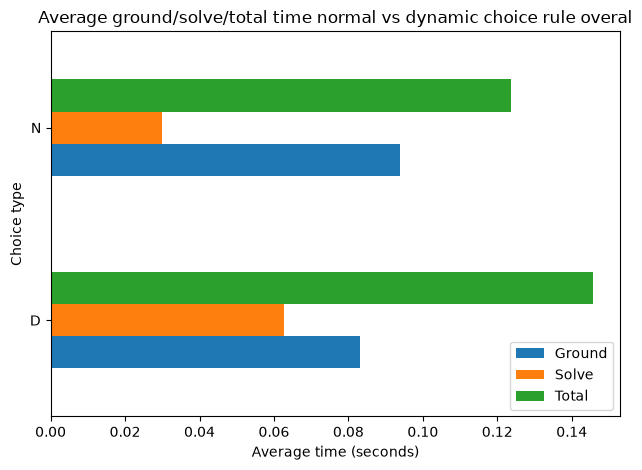

In [311]:
# compare number of ground predicates for at/3 in resulting grounded program
df_choice.groupby('choice_type')[['ground_time','solve_time','total_time']].mean().plot(kind='barh')

plt.title('Average ground/solve/total time normal vs dynamic choice rule overal')
plt.ylabel('Choice type')
plt.xlabel('Average time (seconds)')
plt.legend(['Ground', 'Solve', 'Total'])
plt.tight_layout()
plt.show()

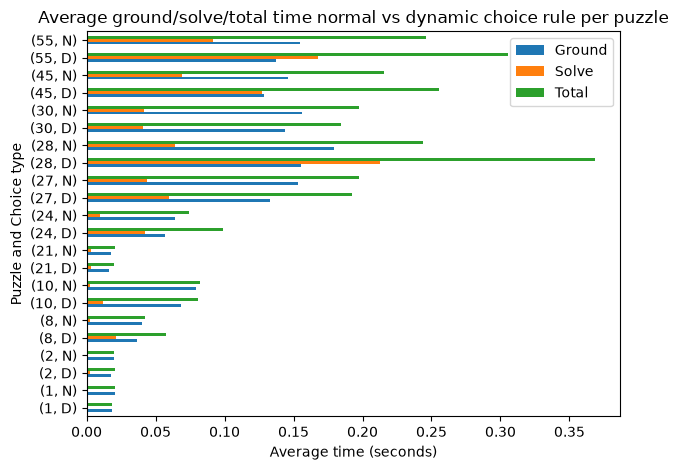

In [314]:
# compare number of ground predicates for at/3 in resulting grounded program
df_choice.groupby(['puzzle', 'choice_type'])[['ground_time','solve_time','total_time']].mean().plot(kind='barh')

plt.title('Average ground/solve/total time normal vs dynamic choice rule per puzzle')
plt.ylabel('Puzzle and Choice type')
plt.xlabel('Average time (seconds)')
plt.legend(['Ground', 'Solve', 'Total'])
plt.tight_layout()
plt.show()

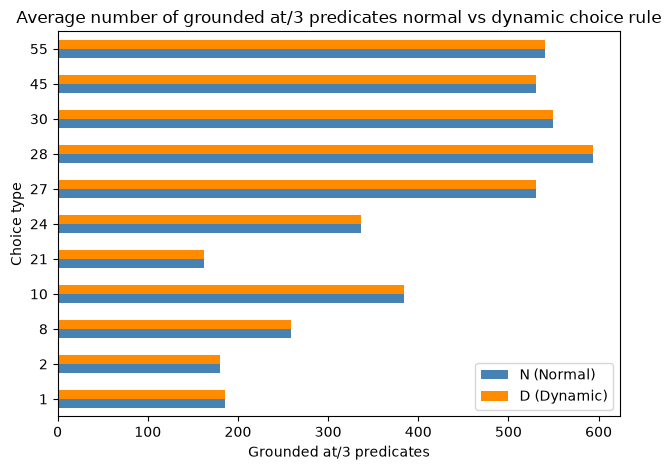

In [313]:
# compare ground_time/solve_time/total_time for both approaches
df_choice.groupby(['puzzle','choice_type'])[['grounded_at']].mean().unstack('choice_type').plot(
    kind='barh', color=['steelblue', 'darkorange']
)

plt.title('Average number of grounded at/3 predicates normal vs dynamic choice rule')
plt.ylabel('Choice type')
plt.xlabel('Grounded at/3 predicates')
plt.legend(['N (Normal)', 'D (Dynamic)'])
plt.tight_layout()
plt.show()

#### Small experiment between normal constraints and aggregate constraints
```ASP
:- person(P1), person(P2), at(P1,R1,C1), at(P2,R2,C2), R1=R2, P1!=P2.
:- person(P1), person(P2), at(P1,R1,C1), at(P2,R2,C2), C1=C2, P1!=P2.
```

VS

```ASP
:- at(_,_,C), #count{P : at(P,R,C)} != 1.
:- at(_,R,_), #count{P : at(P,R,C)} != 1.
```

In [ ]:
epochs=5
puzzles = list(Path('../puzzles').glob("puzzle*.lp"))
results_agg = []

for i in range(epochs):
    print(f'start epoch {i+1}/{epochs}')

    for p in puzzles:
        puzzle_id = p.stem.removeprefix("puzzle")
        puzzle_type = puzzle_id[0]
        puzzle_num = int(puzzle_id.split('-')[1])
        print(f'Puzzle #{puzzle_id}, {puzzle_type}, {puzzle_type == 'A'}')
        result, ground_time, solve_time, grid_size, clue_count, models, grounded_at = solve_puzzle(puzzle_id, puzzle_type == 'A', configuration='auto', base_rules='base-rules.lp')
        result_dyn, ground_time_dyn, solve_time_dyn, grid_size_dyn, clue_count_dyn, models_dyn, grounded_at_dyn = solve_puzzle(puzzle_id, puzzle_type == 'A', configuration='auto', base_rules='base-rules-agg.lp')

        store_result(results_agg, i, puzzle_num, puzzle_type, ground_time, solve_time, ground_time + solve_time, grid_size + 1, clue_count, result.satisfiable, len(models), 'N', grounded_at)
        store_result(results_agg, i, puzzle_num, puzzle_type, ground_time_dyn, solve_time_dyn, ground_time_dyn + solve_time_dyn, grid_size_dyn + 1, clue_count_dyn, result_dyn.satisfiable, len(models_dyn), 'A', grounded_at_dyn)

    print(f'end epoch {i+1}/{epochs}')
    print()
    print('----------------------------------')
    print()

start epoch 1/5
Puzzle #M9-30, M, False
[at(alphonse,1,5), at(charlie,8,6), at(frank,6,7), at(george,7,1), at(victor,0,3), at(bonnie,2,0), at(daisy,3,2), at(emily,4,8), at(hannah,5,4), clue(alphonse,next_to,tv), clue(bonnie,in,kitchen), clue(charlie,next_to,table), clue(charlie,not_in,dining), clue(daisy,only_one_on,chair), clue(emily,on,carpet), clue(frank,next_to,plant), clue(george,on,bed), clue(bonnie,alone), clue(hannah,in_corner)]
SAT
Satisfiable: True
Unsatisfiable: False
Unknown: False
[at(alphonse,1,5), at(charlie,8,6), at(frank,6,7), at(george,7,1), at(victor,0,3), at(bonnie,2,0), at(daisy,3,2), at(emily,4,8), at(hannah,5,4), clue(alphonse,next_to,tv), clue(bonnie,in,kitchen), clue(charlie,next_to,table), clue(charlie,not_in,dining), clue(daisy,only_one_on,chair), clue(emily,on,carpet), clue(frank,next_to,plant), clue(george,on,bed), clue(bonnie,alone), clue(hannah,in_corner)]
SAT
Satisfiable: True
Unsatisfiable: False
Unknown: False
Puzzle #M9-55, M, False
[at(alice,3,3), at

In [318]:
# put results in pandas dataframe
# put results in pandas frame
df_agg = pd.DataFrame(results_agg)
df_agg.head()


,epoch,puzzle,type,ground_time,solve_time,total_time,grid_size,clue_count,solve_state,num_solutions,choice_type,grounded_at
0,0,30,M,0.178772,0.041935,0.220707,9,10,True,1,N,549
1,0,30,M,0.133195,0.016910,0.150105,9,10,True,1,D,549
2,0,55,M,0.155972,0.088938,0.244909,9,14,True,1,N,540
3,0,55,M,0.140951,0.131588,0.272539,9,14,True,1,D,540
4,0,45,M,0.146470,0.066967,0.213437,9,12,True,1,N,531


In [320]:
# check for failed solutions or multiple solutions
failed_agg = df_agg[df_agg['solve_state'] == False]
len(failed_agg)

0

In [321]:
# check for failed solutions or multiple solutions
wrong_sol_agg = df_agg[df_agg['num_solutions'] != 1]
len(wrong_sol_agg)

0

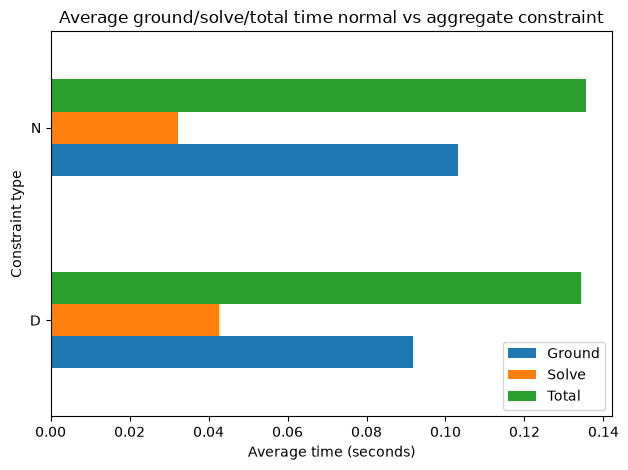

In [322]:
# compare number of ground predicates for at/3 in resulting grounded program
df_agg.groupby('choice_type')[['ground_time','solve_time','total_time']].mean().plot(kind='barh')

plt.title('Average ground/solve/total time normal vs aggregate constraint')
plt.ylabel('Constraint type')
plt.xlabel('Average time (seconds)')
plt.legend(['Ground', 'Solve', 'Total'])
plt.tight_layout()
plt.show()

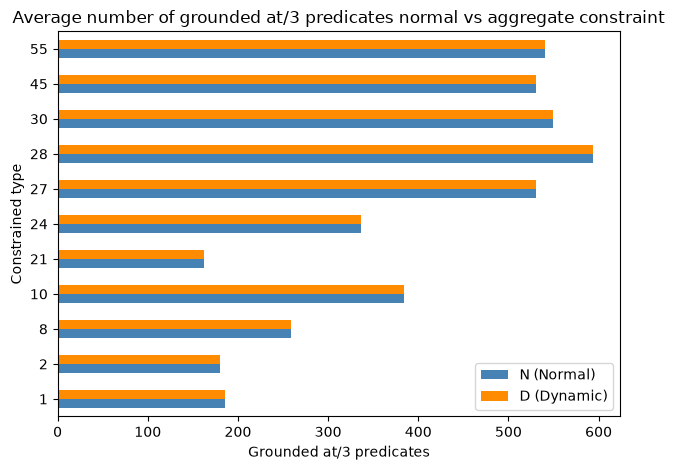

In [323]:
# compare ground_time/solve_time/total_time for both approaches
df_agg.groupby(['puzzle','choice_type'])[['grounded_at']].mean().unstack('choice_type').plot(
    kind='barh', color=['steelblue', 'darkorange']
)

plt.title('Average number of grounded at/3 predicates normal vs aggregate constraint')
plt.ylabel('Constrained type')
plt.xlabel('Grounded at/3 predicates')
plt.legend(['N (Normal)', 'D (Dynamic)'])
plt.tight_layout()
plt.show()

### Run main experiment
- epoch is one run of all available puzzles
- type 'M' puzzles are manually taken from Murdoku book 1
- type 'A' puzzles are automatically generated with our Murdoku-generator
- statistics like grounding time, solving time, total time, grid size and number of clues are store per puzzle per epoch, these can later be used for analysis


In [ ]:
# number of runs for experiment
epochs = 1


puzzles = list(Path('../puzzles').glob("puzzle*.lp"))
puzzles_gen = list(Path('../autogenerated_puzzles/puzzles').glob('puzzle*.lp'))
puzzles.extend(puzzles_gen)
results = []
for i in range(epochs):
    print(f'start epoch {i+1}/{epochs}')

    for p in puzzles:
        puzzle_id = p.stem.removeprefix("puzzle")
        puzzle_type = puzzle_id[0]
        puzzle_num = int(puzzle_id.split('-')[1])
        print(f'Puzzle #{puzzle_id}, {puzzle_type}, {puzzle_type == 'A'}')
        result, ground_time, solve_time, grid_size, clue_count, models = solve_puzzle(puzzle_id, puzzle_type == 'A', configuration='auto', base_rules='base_rules.lp')
        results.append({
            'epoch': i, # epoch
            'puzzle': puzzle_num, # puzzle number
            'type': puzzle_type, # automated puzzles with 'type': 'A' manual with 'M', comes from file names.
            'ground_time': ground_time, # time spent on grounding all possibilities
            'solve_time': solve_time, # time spent on solving all grounded rules
            'total_time': ground_time + solve_time, # total time
            'grid_size': grid_size + 1, # grid size of puzzle X*X
            'clue_count': clue_count, # number of clues
            'solve_state': result.satisfiable, # is puzzle satisfiable
            'num_solutions': len(models) # number of solutions, should always be 1
        })

    print(f'end epoch {i+1}/{epochs}')
    print()
    print('----------------------------------')
    print()

print('ground times:')
for i in range(epochs):
    print(f'epoch {i+1}:') 
    print(f'ground_times: {[x['ground_time'] for x in results if x['epoch'] == i]}')
    print(f'solve_times: {[x['solve_time'] for x in results if x['epoch'] == i]}')
    print(f'total_times: {[x['total_time'] for x in results if x['epoch'] == i]}')
    print(f'grid_sizes: {[x['grid_size'] for x in results if x['epoch'] == i]}')
    print()

start epoch 1/1
Puzzle #M9-30, M, False
[at(alphonse,1,5), at(bonnie,2,0), at(charlie,8,6), at(daisy,3,2), at(emily,4,8), at(frank,6,7), at(george,7,1), at(hannah,5,4), at(victor,0,3), murderer(alphonse), clue(alphonse,next_to,tv), clue(bonnie,in,kitchen), clue(charlie,next_to,table), clue(charlie,not_in,dining), clue(daisy,only_one_on,chair), clue(emily,on,carpet), clue(frank,next_to,plant), clue(george,on,bed), clue(bonnie,alone), clue(hannah,in_corner)]
SAT
Satisfiable: True
Unsatisfiable: False
Unknown: False
Puzzle #M9-45, M, False
[at(alphonse,4,5), at(bernard,3,4), at(carol,1,7), at(daisy,7,6), at(emily,0,3), at(frank,8,1), at(george,2,0), at(henry,5,8), at(victor,6,2), murderer(frank), clue(alphonse,in,mainfloor), clue(alphonse,east_of,emily), clue(alphonse,south_of,bernard), clue(bernard,next_to_with_someone_else,plant), clue(daisy,only_one_on,chair), clue(emily,in_row,0), clue(frank,next_to,tv), clue(george,next_to,table), clue(george,next_to,chair), clue(henry,only_one_on,wi

### Analyze
- check for unsatisfiable puzzles
- check for puzzles with multiple solutions
- convert results to Pandas DataFrame for easy evaluation
- Compare performance between puzzles (commented out)
- Compare performance between grid sizes
- Compare performance between number of clues
- Compare performance between generated and manual puzzles
- Compare performance between combination of grid size and number of clues
- Compare performance between combination of grid size and generated/manual

In [254]:
df = pd.DataFrame(results)
df.head()


,epoch,puzzle,type,ground_time,solve_time,total_time,grid_size,clue_count,solve_state,num_solutions
0,0,30,M,0.165353,0.064001,0.229354,9,10,True,1
1,0,45,M,0.140822,0.084491,0.225313,9,12,True,1
2,0,1,M,0.020237,0.000097,0.020334,6,5,True,1
3,0,10,M,0.073817,0.003441,0.077258,8,9,True,1
4,0,24,M,0.060723,0.012194,0.072917,8,10,True,1


In [255]:
# unsolved = df[~df['solve_state']]
# unsolved.sum()
(~df['solve_state']).sum()

np.int64(0)

In [256]:
multi_solutions = df[(df['num_solutions'] > 1) & (df['epoch'] == 0)]
multi_solutions

,epoch,puzzle,type,ground_time,solve_time,total_time,grid_size,clue_count,solve_state,num_solutions


In [239]:
df[(df['puzzle']==1) & (df['grid_size']==11)]

,epoch,puzzle,type,ground_time,solve_time,total_time,grid_size,clue_count,solve_state,num_solutions
483,0,1,A,0.587561,0.578856,1.166417,11,18,True,1


In [240]:
df.groupby('puzzle')[['ground_time', 'solve_time', 'total_time']].mean()

,ground_time,solve_time,total_time
puzzle,,,
1,0.150346,0.096850,0.247196
2,0.158316,0.743289,0.901605
3,0.175248,0.078590,0.253837
4,0.104929,0.051497,0.156427
5,0.111627,0.086437,0.198064
...,...,...,...
96,0.111725,0.056551,0.168275
97,0.112015,0.084707,0.196722
98,0.108109,0.042743,0.150852


In [241]:
df.groupby('grid_size')[['ground_time', 'solve_time', 'total_time']].mean()

,ground_time,solve_time,total_time
grid_size,,,
4,0.003783,0.000329,0.004112
5,0.009235,0.001381,0.010616
6,0.021491,0.003923,0.025414
7,0.046995,0.014286,0.061282
8,0.096156,0.051067,0.147223
9,0.191893,0.135699,0.327592
10,0.361391,0.591928,0.953319
11,0.645106,2.302929,2.948034


In [242]:
# df.groupby('puzzle')[['ground_time','solve_time','total_time']].mean().plot(kind='barh')

# plt.ylabel('Puzzle')
# plt.xlabel('Average time (seconds)')
# plt.title('Average ground/solve/total time per puzzle')
# plt.legend(['Ground', 'Solve', 'Total'])
# plt.tight_layout()
# plt.show()

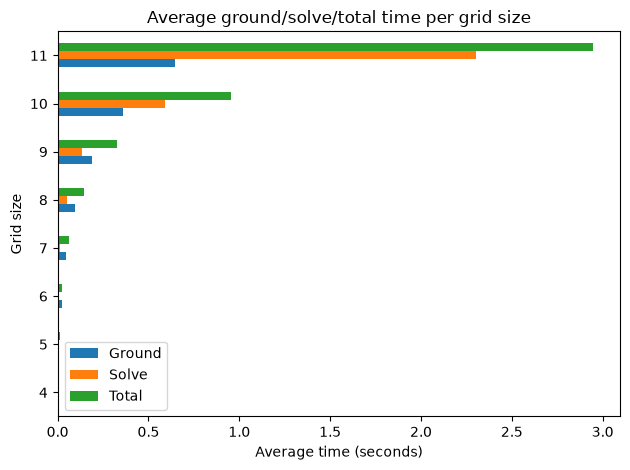

In [243]:
df.groupby('grid_size')[['ground_time','solve_time','total_time']].mean().plot(kind='barh')

plt.ylabel('Grid size')
plt.xlabel('Average time (seconds)')
plt.title('Average ground/solve/total time per grid size')
plt.legend(['Ground', 'Solve', 'Total'])
plt.tight_layout()
plt.show()

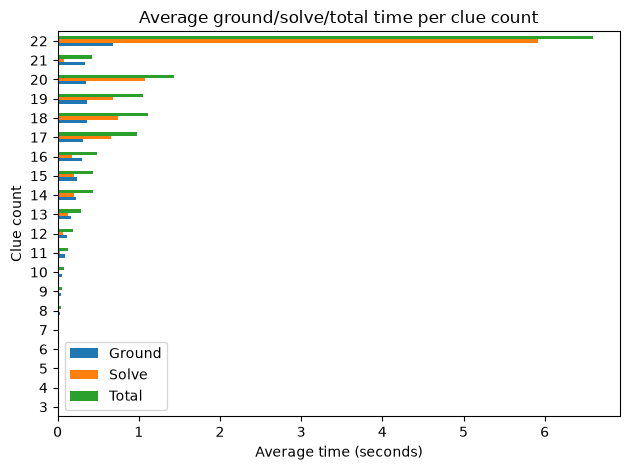

In [244]:
df.groupby('clue_count')[['ground_time','solve_time','total_time']].mean().plot(kind='barh')

plt.ylabel('Clue count')
plt.xlabel('Average time (seconds)')
plt.title('Average ground/solve/total time per clue count')
plt.legend(['Ground', 'Solve', 'Total'])
plt.tight_layout()
plt.show()

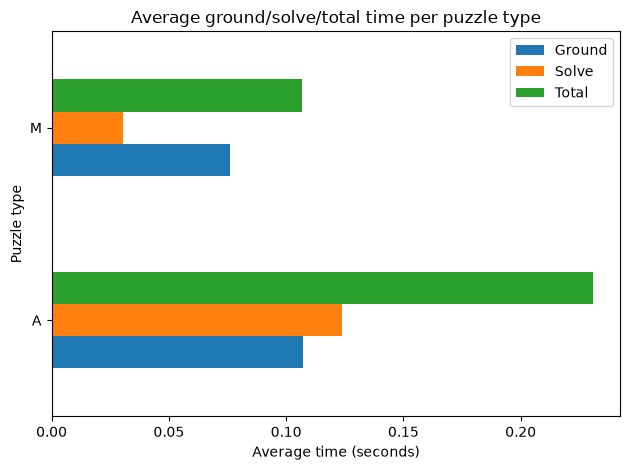

In [245]:
df.groupby('type')[['ground_time','solve_time','total_time']].mean().plot(kind='barh')

plt.ylabel('Puzzle type')
plt.xlabel('Average time (seconds)')
plt.title('Average ground/solve/total time per puzzle type')
plt.legend(['Ground', 'Solve', 'Total'])
plt.tight_layout()
plt.show()

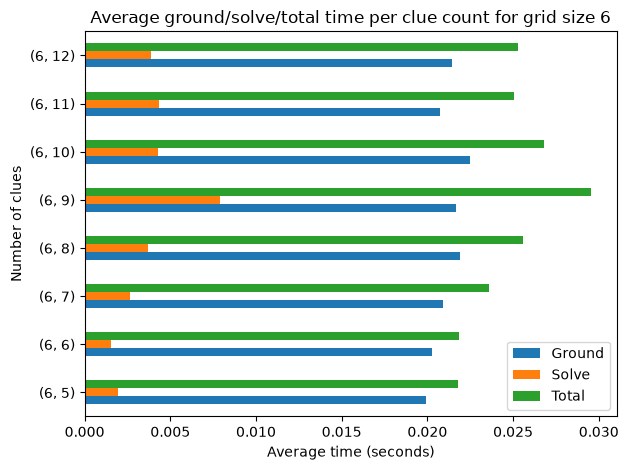

In [246]:
df_6 = df[df['grid_size'] == 6]
df_6.groupby(['grid_size','clue_count'])[['ground_time','solve_time','total_time']].mean().plot(kind='barh')

plt.ylabel('Number of clues')
plt.xlabel('Average time (seconds)')
plt.title('Average ground/solve/total time per clue count for grid size 6')
plt.legend(['Ground', 'Solve', 'Total'])
plt.tight_layout()
plt.show()

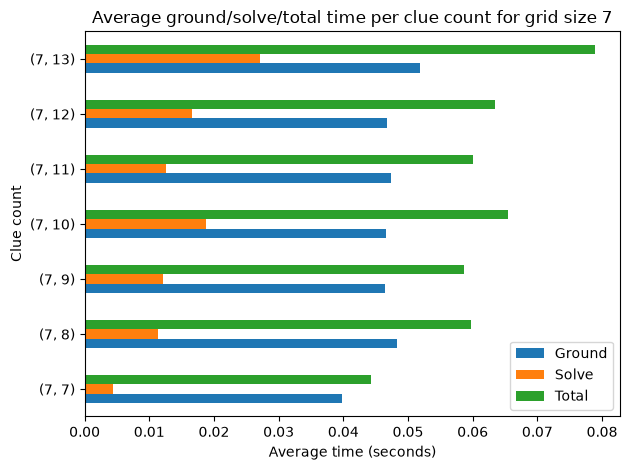

In [247]:
df_7 = df[df['grid_size'] == 7]
df_7.groupby(['grid_size','clue_count'])[['ground_time','solve_time','total_time']].mean().plot(kind='barh')

plt.ylabel('Clue count')
plt.xlabel('Average time (seconds)')
plt.title('Average ground/solve/total time per clue count for grid size 7')
plt.legend(['Ground', 'Solve', 'Total'])
plt.tight_layout()
plt.show()

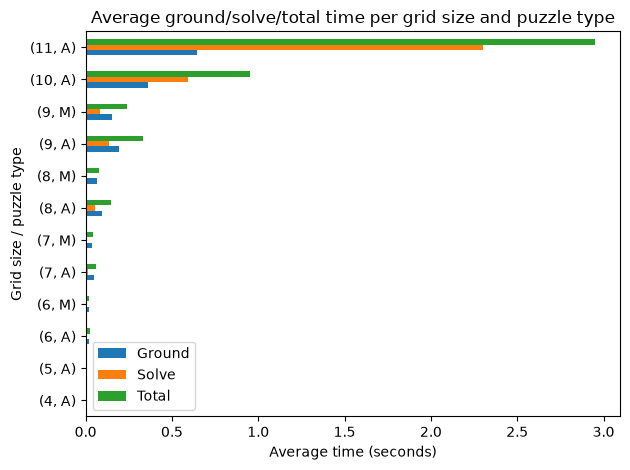

In [248]:
df.groupby(['grid_size', 'type'])[['ground_time','solve_time','total_time']].mean().plot(kind='barh')

plt.ylabel('Grid size / puzzle type')
plt.xlabel('Average time (seconds)')
plt.title('Average ground/solve/total time per grid size and puzzle type')
plt.legend(['Ground', 'Solve', 'Total'])
plt.tight_layout()
plt.show()